# Look at the crops

Shows the building crops made by `scripts/extract_crops.py`. Use it to check that the crops are
sensible before training, and to make figures for the report.

- One sample = the **same box** cut from the pre image and from the post image.
- The damage label comes from the post image, so always read the two rows together.
- Nothing here changes the data. It only reads `crops/wind_64/`.

## 1. Settings

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CROPS_DIR = Path("../crops/wind_64")        # folder made by scripts/extract_crops.py
OUT_DIR = Path("../reports/eda")
SEED = 0

OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

CLASS_NAME = {0: "no-damage", 1: "minor-damage", 2: "major-damage", 3: "destroyed"}
CLASS_COLOR = {0: "lime", 1: "yellow", 2: "orange", 3: "red"}
SPLIT_ORDER = ["source_train", "source_val", "target_train", "target_test", "test"]

info = json.loads((CROPS_DIR / "extract_info.json").read_text())
man = pd.read_csv(CROPS_DIR / "manifest.csv")
man = man[man["ok"]].copy()                  # drop rows whose image could not be read

print(f"crop size      : {info['size']} px")
print(f"box rule       : clip({info['box_scale']} x side, {info['min_box']}, {info['max_box']}) px")
print(f"domains        : source={info['source']}  target={info['target']}  test={info['test']}")
print(f"crops available: {len(man):,}")


def save_fig(name):
    """Save the current figure into reports/eda/."""
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

crop size      : 64 px
box rule       : clip(1.5 x side, 16, 256) px
domains        : source=us-central  target=us-south  test=caribbean
crops available: 108,916


## 2. Load the arrays

The `.npy` files are opened with `mmap_mode="r"`, so nothing is copied into memory. Only the
crops you actually display are read from disk.

In [2]:
_cache = {}


def array(split, when):
    """The (n, size, size, 3) uint8 array of one split. 'when' is 'pre' or 'post'."""
    key = (split, when)
    if key not in _cache:
        _cache[key] = np.load(CROPS_DIR / f"{split}_{when}.npy", mmap_mode="r")
    return _cache[key]


def crops_of(rows):
    """Pre and post crops for a slice of the manifest, in the order of the rows given."""
    pre = np.stack([array(r.split, "pre")[r.row] for r in rows.itertuples()])
    post = np.stack([array(r.split, "post")[r.row] for r in rows.itertuples()])
    return pre, post


for split in SPLIT_ORDER:
    if (CROPS_DIR / f"{split}_pre.npy").exists():
        a = array(split, "pre")
        print(f"{split:14} {a.shape}  {a.dtype}  {a.nbytes / 1e6:7,.0f} MB on disk")

source_train   (29619, 64, 64, 3)  uint8      364 MB on disk
source_val     (7446, 64, 64, 3)  uint8       91 MB on disk
target_train   (38901, 64, 64, 3)  uint8      478 MB on disk
target_test    (10322, 64, 64, 3)  uint8      127 MB on disk
test           (22628, 64, 64, 3)  uint8      278 MB on disk


## 3. What is in each split

In [3]:
counts = man.pivot_table(index="split", columns="label_id", values="building_uid",
                         aggfunc="count", fill_value=0)
counts.columns = [CLASS_NAME[c] for c in counts.columns]
counts = counts.reindex([s for s in SPLIT_ORDER if s in counts.index])
counts["total"] = counts.sum(axis=1)
display(counts)

print("Class share per split (%)")
display((100 * counts[counts.columns[:-1]].div(counts["total"], axis=0)).round(1))

print("Events per split")
display(man.groupby("split")["event"].unique().reindex(
    [s for s in SPLIT_ORDER if s in set(man["split"])]).to_frame("events"))

,no-damage,minor-damage,major-damage,destroyed,total
split,,,,,
source_train,22658,2462,1135,3364,29619
source_val,5018,615,319,1494,7446
target_train,26492,7918,2693,1798,38901
target_test,6696,2410,692,524,10322
test,4058,12331,2717,3522,22628


Class share per split (%)


,no-damage,minor-damage,major-damage,destroyed
split,,,,
source_train,76.5,8.3,3.8,11.4
source_val,67.4,8.3,4.3,20.1
target_train,68.1,20.4,6.9,4.6
target_test,64.9,23.3,6.7,5.1
test,17.9,54.5,12.0,15.6


Events per split


,events
split,
source_train,"[joplin-tornado, moore-tornado]"
source_val,"[joplin-tornado, moore-tornado]"
target_train,"[hurricane-michael, tuscaloosa-tornado]"
target_test,"[hurricane-michael, tuscaloosa-tornado]"
test,[hurricane-matthew]


## 4. The display function

Top row = pre-disaster, bottom row = post-disaster. The title colour is the damage class.

In [4]:
def show_pairs(rows, title="", subtitle=None, ncols=10, save=None):
    """Show the pre (top) and post (bottom) crop of every row given."""
    rows = rows.head(ncols)
    if rows.empty:
        print(f"{title}: nothing to show")
        return
    pre, post = crops_of(rows)
    n = len(rows)

    fig, axes = plt.subplots(2, n, figsize=(1.35 * n, 3.3), squeeze=False)
    for i, (_, r) in enumerate(rows.iterrows()):
        for j, img in ((0, pre[i]), (1, post[i])):
            axes[j][i].imshow(img)
            axes[j][i].set_xticks([])
            axes[j][i].set_yticks([])
            for s in axes[j][i].spines.values():
                s.set_color(CLASS_COLOR[r.label_id])
                s.set_linewidth(2)
        text = subtitle(r) if subtitle else f"{int(r.side)} px"
        axes[0][i].set_title(text, fontsize=8, color="black")
    axes[0][0].set_ylabel("pre", fontsize=9)
    axes[1][0].set_ylabel("post", fontsize=9)
    fig.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    if save:
        save_fig(save)
    plt.show()


def sample(df, n, **where):
    """n random rows matching the given column values, e.g. sample(man, 8, split='test', label_id=3)."""
    sel = df
    for col, val in where.items():
        sel = sel[sel[col] == val]
    if sel.empty:
        return sel
    return sel.sample(min(n, len(sel)), random_state=SEED)

## 5. Samples of each damage class

From the source training split. The border colour is the class: green = no-damage,
yellow = minor, orange = major, red = destroyed.

This is the first thing to check. If you cannot see the difference between the pre and post
crop of a "destroyed" building, something is wrong with the boxes or the paths.

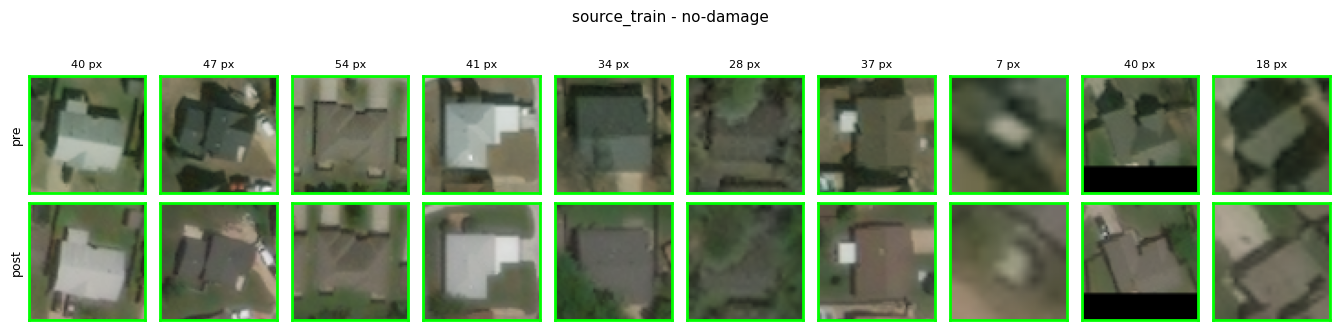

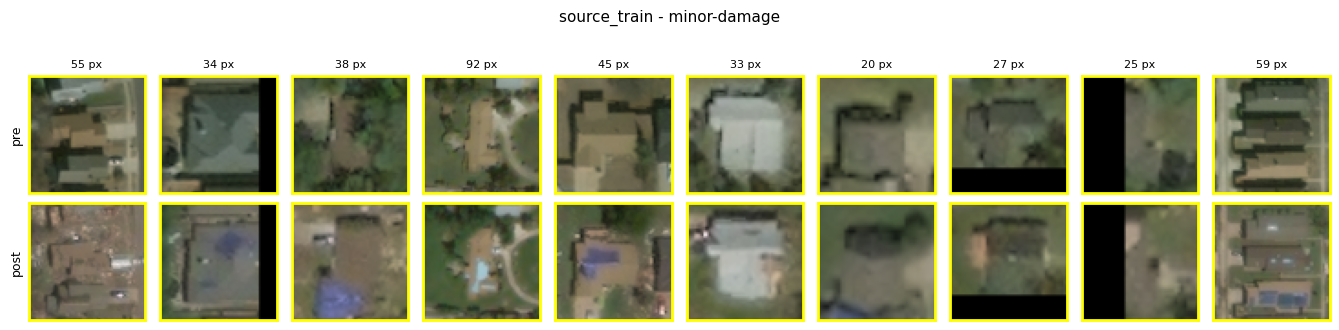

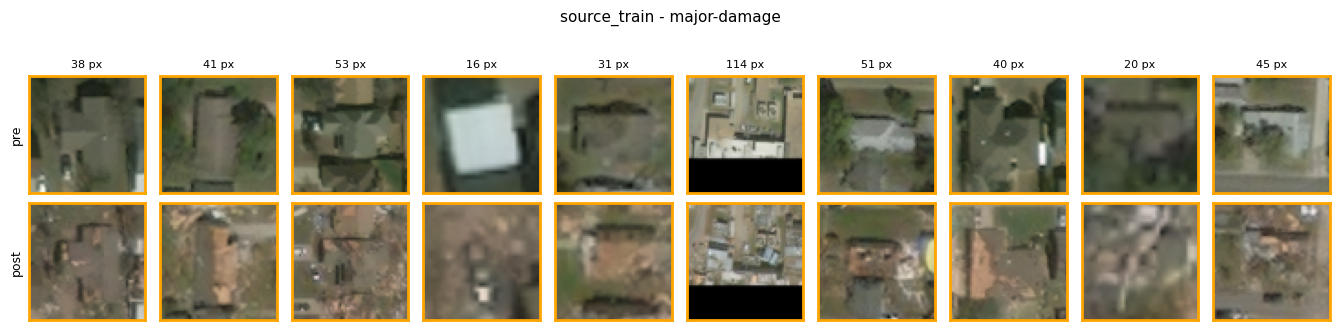

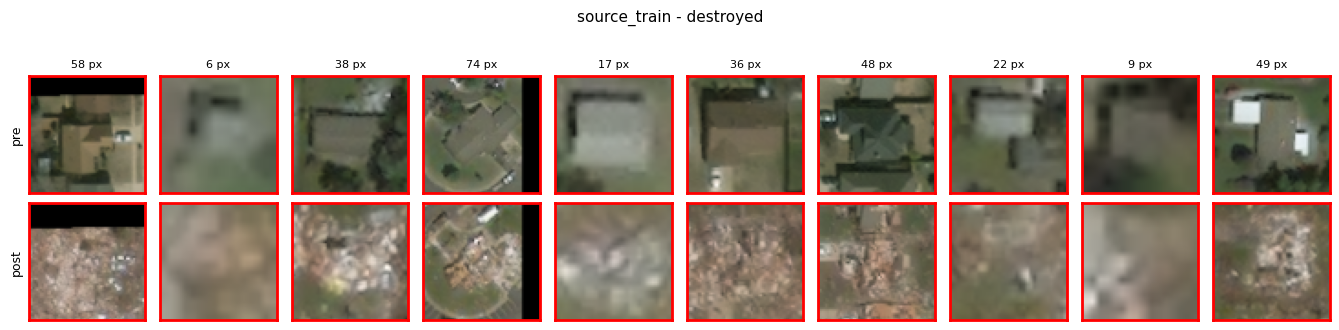

In [5]:
for label_id, name in CLASS_NAME.items():
    rows = sample(man, 10, split="source_train", label_id=label_id)
    show_pairs(rows, title=f"source_train - {name}", save=f"crops_class_{label_id}_{name}")

## 6. The same class across the three domains

This is the domain shift, seen directly. Pick one class and compare the rows: colour, resolution,
roof type and building size all change between the US events and Haiti.
Good material for the report.

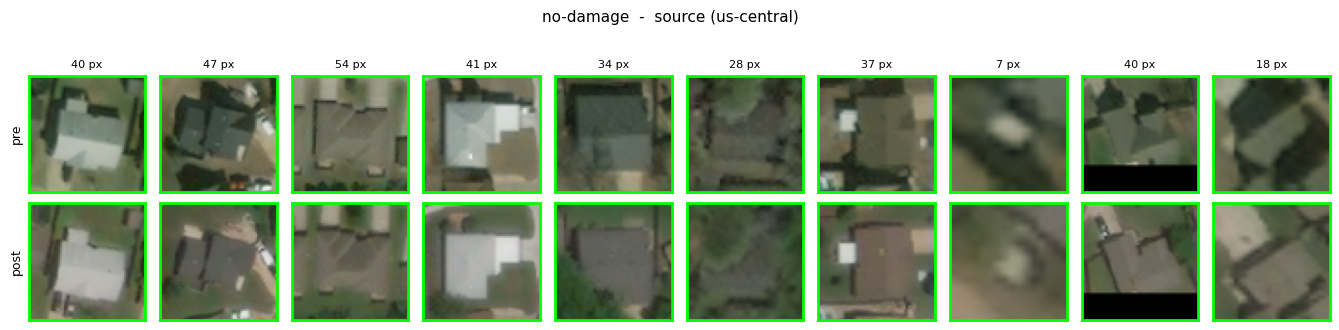

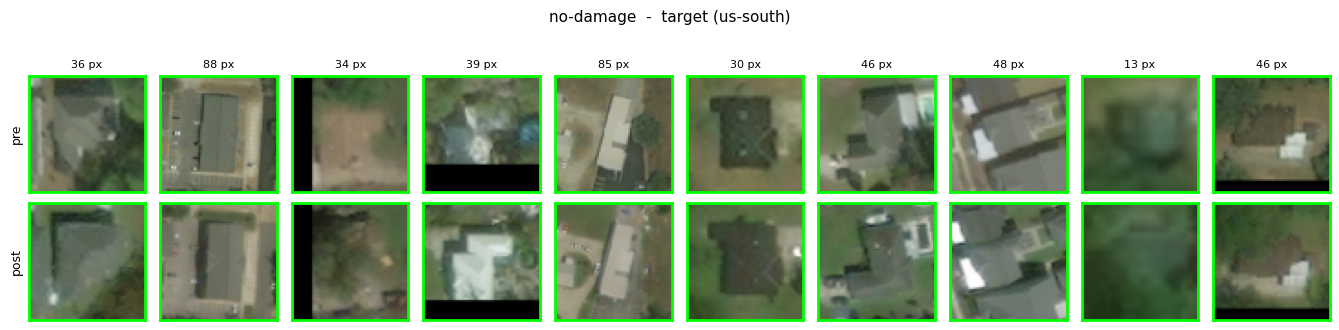

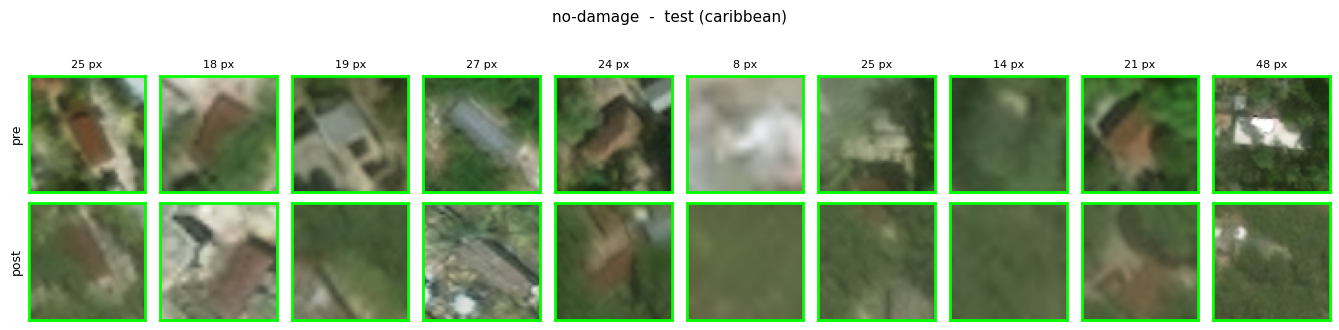

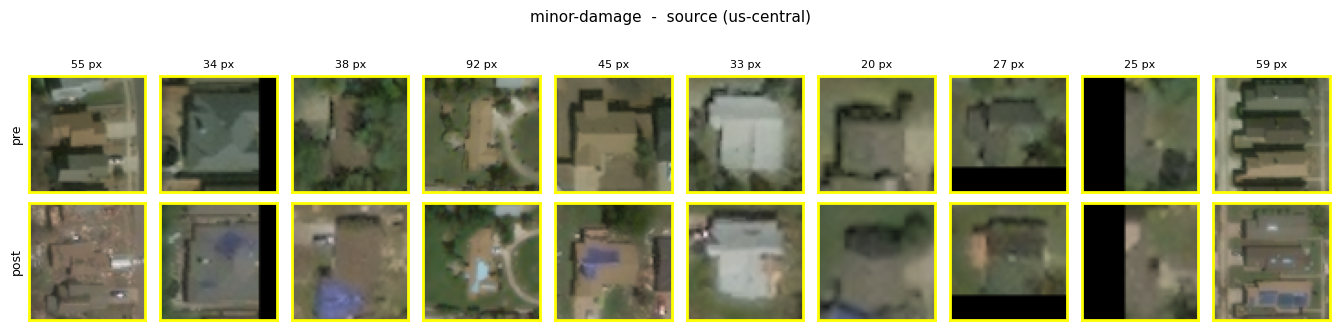

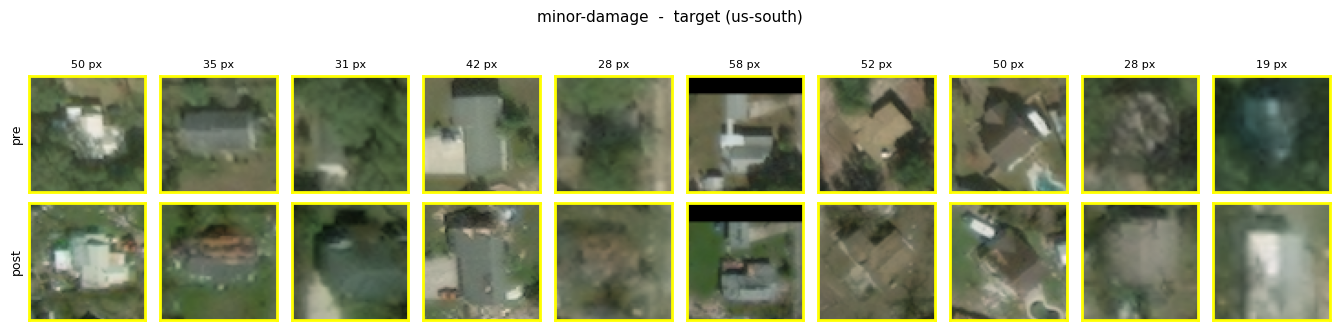

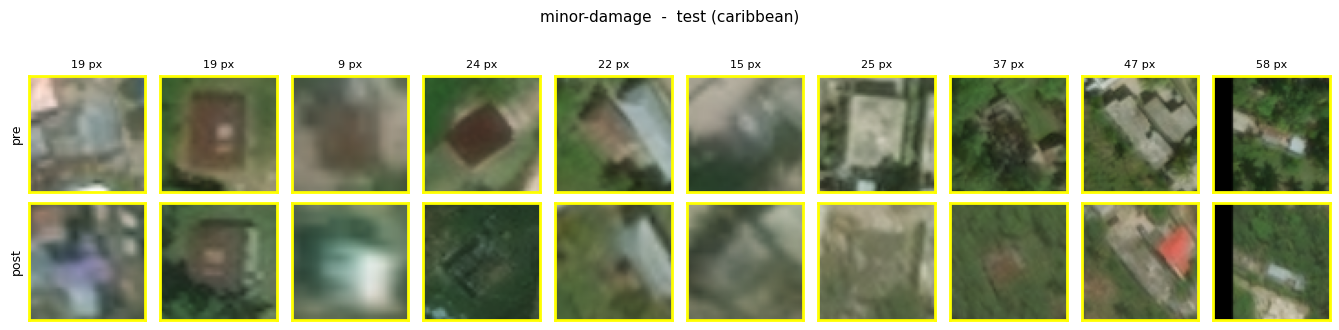

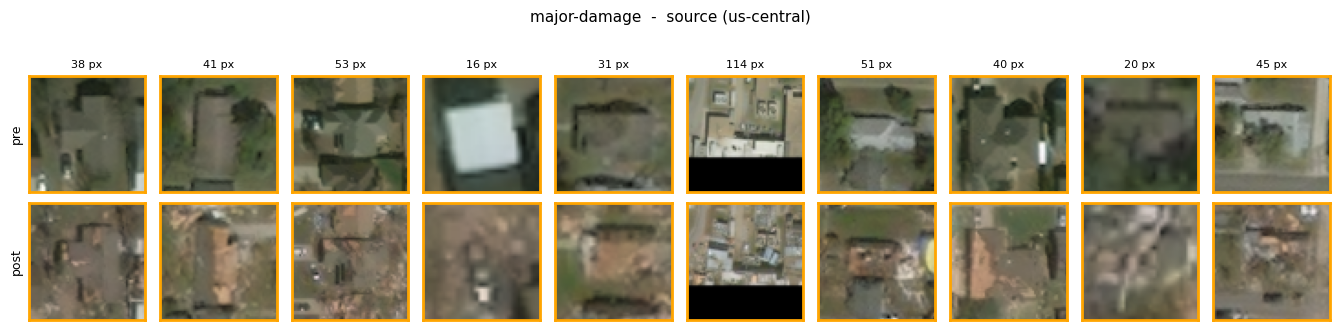

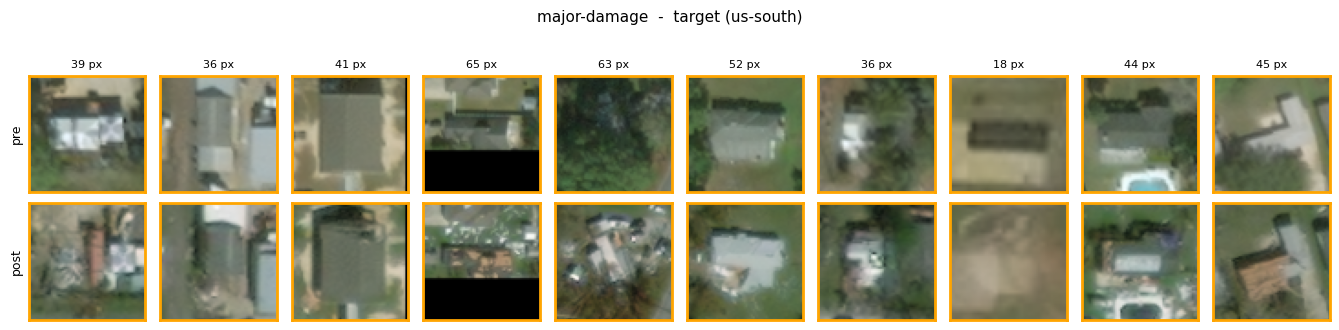

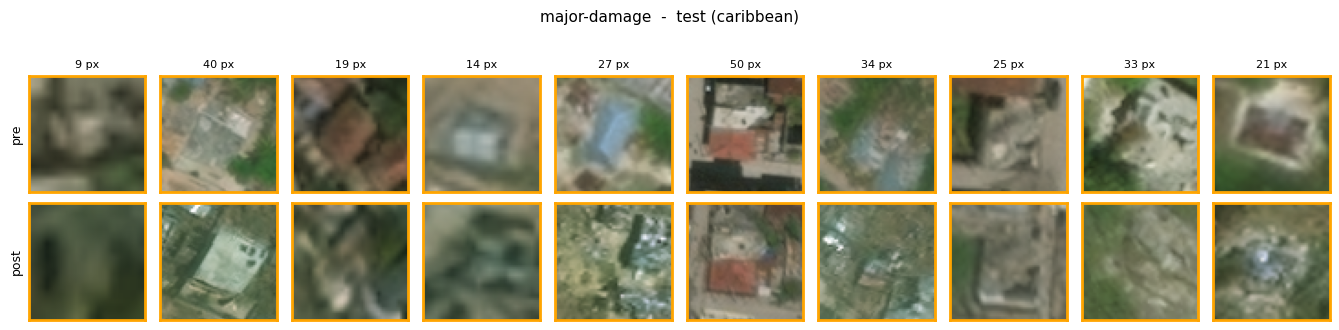

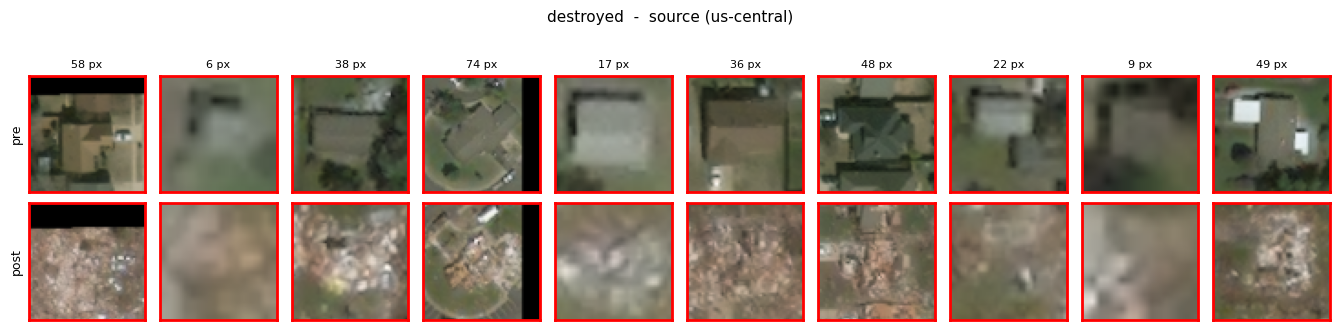

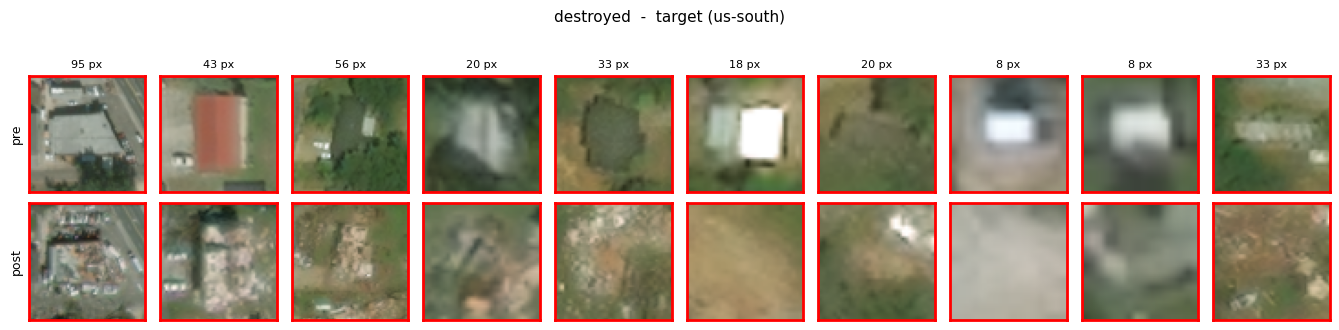

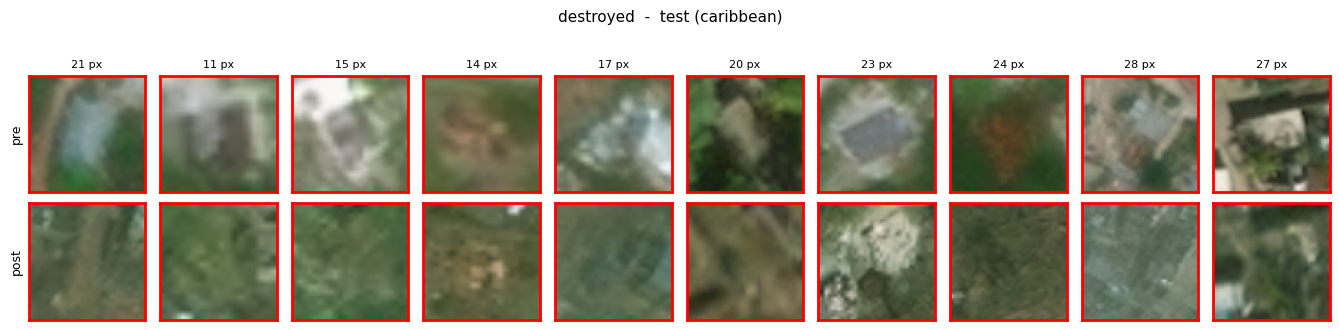

In [6]:
DOMAIN_SPLIT = {"source (us-central)": "source_train",
                "target (us-south)": "target_train",
                "test (caribbean)": "test"}

for label_id, name in CLASS_NAME.items():
    for domain, split in DOMAIN_SPLIT.items():
        rows = sample(man, 10, split=split, label_id=label_id)
        show_pairs(rows, title=f"{name}  -  {domain}",
                   save=f"crops_domain_{label_id}_{split}")

## 7. Samples per event

Same idea, one row block per event, so you can see how different joplin, moore, tuscaloosa,
michael and matthew look.

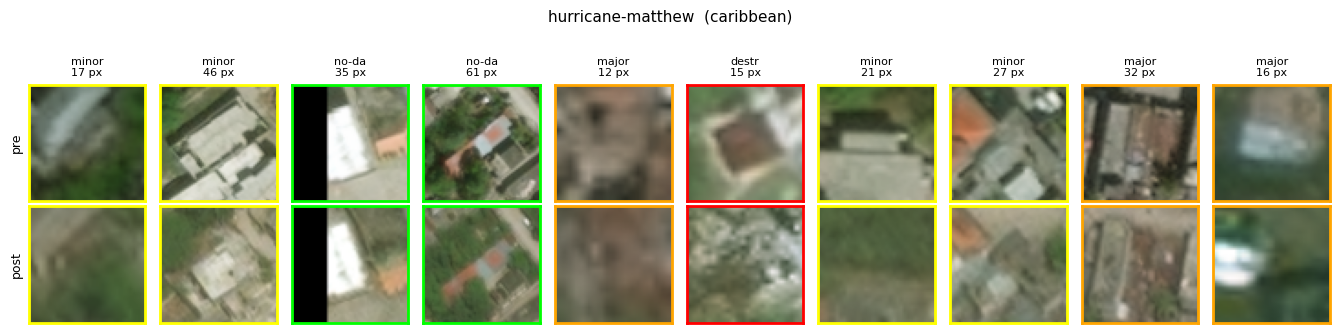

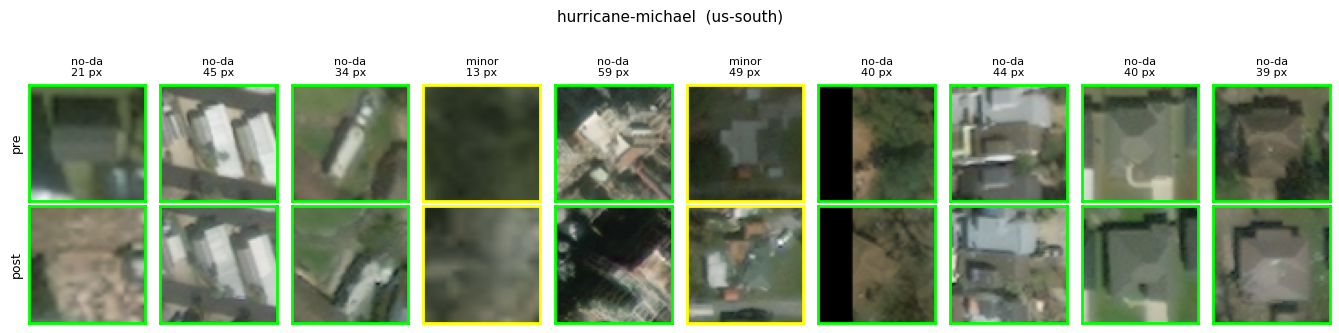

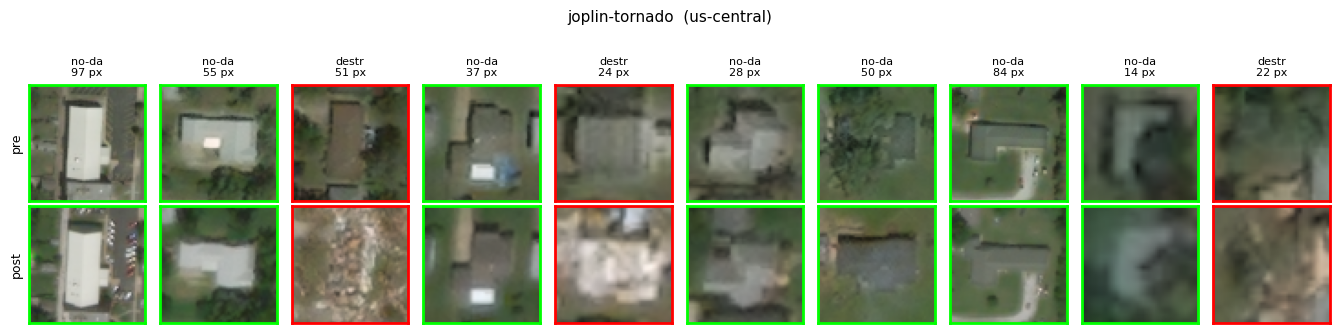

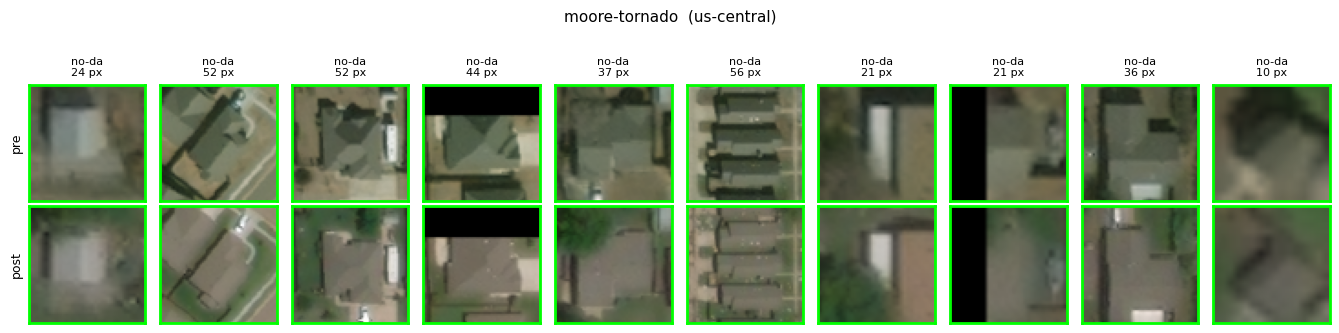

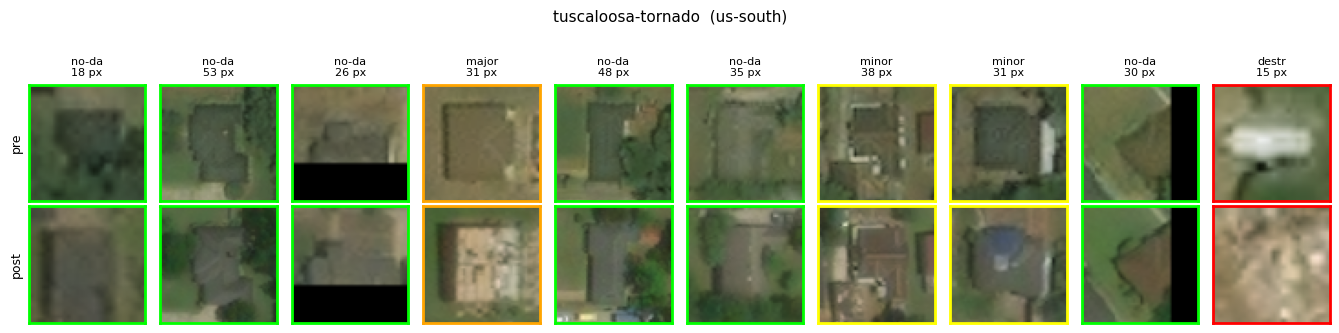

In [7]:
for event in sorted(man["event"].unique()):
    rows = sample(man, 10, event=event)
    show_pairs(rows, title=f"{event}  ({man[man.event == event]['location'].iloc[0]})",
               subtitle=lambda r: f"{CLASS_NAME[r.label_id][:5]}\n{int(r.side)} px",
               save=f"crops_event_{event}")

## 8. The extreme cases

Checks that the box rule behaved. Three things to look at:

- **Smallest buildings**: the crop box has hit the 16 px floor, so the building is small inside the crop.
  Expect blurry images. If they are pure noise, consider raising `--min-side`.
- **Largest buildings**: the box has hit the 256 px cap, so the building may be cut off.
- **Most black**: no-data borders. Only 0.06 % of crops are over half black, so these should be rare.

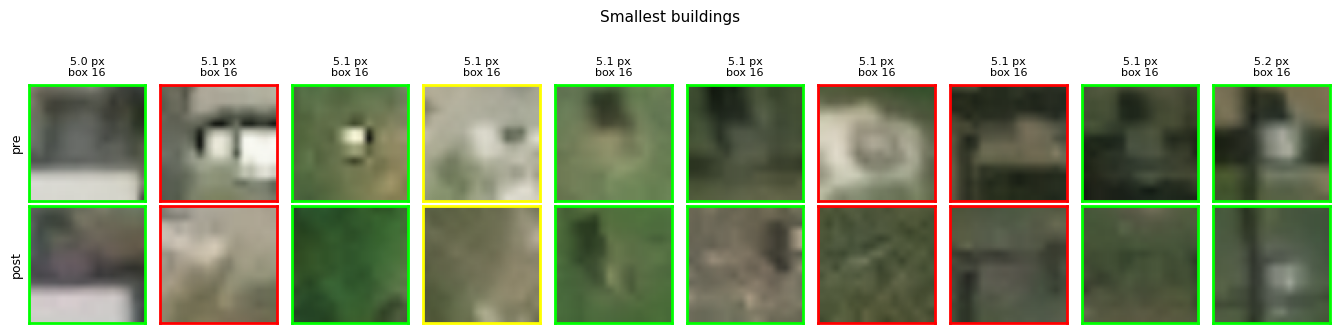

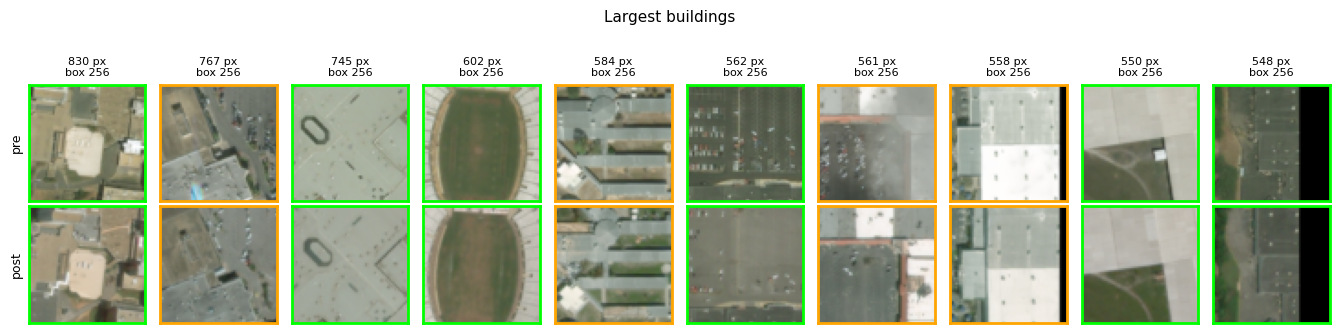

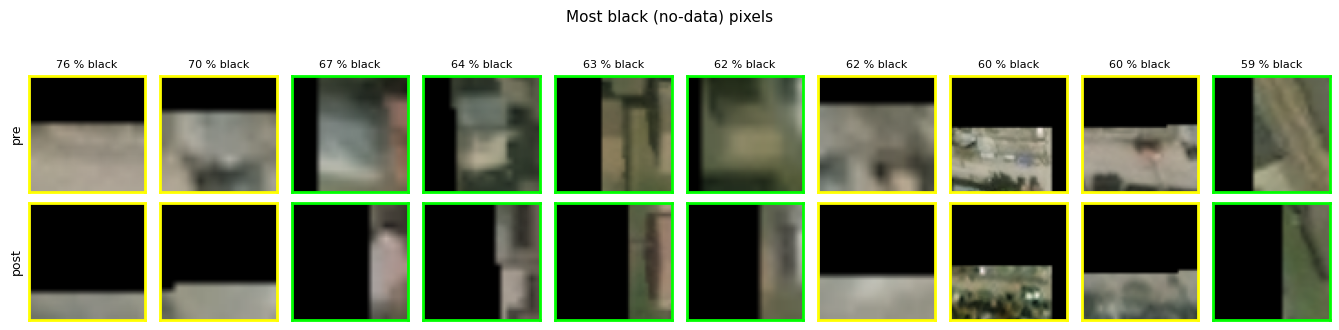

crops over 50 % black: 69 (0.06 %)


In [8]:
show_pairs(man.nsmallest(10, "side"), title="Smallest buildings",
           subtitle=lambda r: f"{r.side:.1f} px\nbox {r.box:.0f}", save="crops_smallest")

show_pairs(man.nlargest(10, "side"), title="Largest buildings",
           subtitle=lambda r: f"{r.side:.0f} px\nbox {r.box:.0f}", save="crops_largest")

man["black_max"] = man[["black_pre", "black_post"]].max(axis=1)
show_pairs(man.nlargest(10, "black_max"), title="Most black (no-data) pixels",
           subtitle=lambda r: f"{100 * r.black_max:.0f} % black", save="crops_blackest")

print(f"crops over 50 % black: {(man.black_max > 0.5).sum():,} "
      f"({100 * (man.black_max > 0.5).mean():.2f} %)")

## 9. Average crop per class and domain

The mean of all crops in a group. It is not a real building, but it shows the average colour and
brightness. Big differences between the domains here mean the normalisation and the colour
statistics differ, which is exactly what CORAL tries to fix.

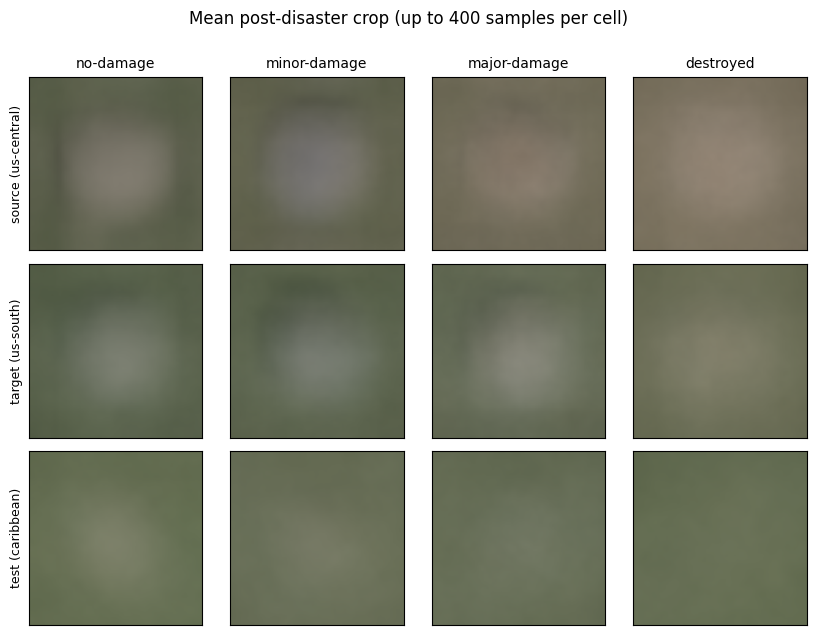

In [9]:
fig, axes = plt.subplots(len(DOMAIN_SPLIT), len(CLASS_NAME),
                         figsize=(2.1 * len(CLASS_NAME), 2.1 * len(DOMAIN_SPLIT)), squeeze=False)
for i, (domain, split) in enumerate(DOMAIN_SPLIT.items()):
    for j, (label_id, name) in enumerate(CLASS_NAME.items()):
        sel = man[(man.split == split) & (man.label_id == label_id)]
        ax = axes[i][j]
        ax.set_xticks([])
        ax.set_yticks([])
        if sel.empty:
            ax.axis("off")
            continue
        sel = sel.sample(min(400, len(sel)), random_state=SEED)
        post = crops_of(sel)[1].astype(np.float32).mean(axis=0) / 255.0
        ax.imshow(np.clip(post, 0, 1))
        if i == 0:
            ax.set_title(name, fontsize=10)
        if j == 0:
            ax.set_ylabel(domain, fontsize=9)
fig.suptitle("Mean post-disaster crop (up to 400 samples per cell)", fontsize=12, y=1.0)
plt.tight_layout()
save_fig("crops_mean_by_domain")
plt.show()

In [10]:
print("Mean RGB of the post crops, per domain (0-255)")
rows = []
for domain, split in DOMAIN_SPLIT.items():
    sel = man[man.split == split].sample(min(2000, (man.split == split).sum()), random_state=SEED)
    post = crops_of(sel)[1].astype(np.float32)
    rows.append({"domain": domain, "R": float(post[..., 0].mean()), "G": float(post[..., 1].mean()),
                 "B": float(post[..., 2].mean()), "std": float(post.std())})
display(pd.DataFrame(rows).set_index("domain").round(1))

Mean RGB of the post crops, per domain (0-255)


,R,G,B,std
domain,,,,
source (us-central),102.4,102.7,85.4,37.5
target (us-south),94.5,102.2,81.9,40.7
test (caribbean),104.3,110.9,86.7,38.2


In [11]:
def sharpness(a):
    """Mean squared gradient of the greyscale crop. Higher = sharper."""
    g = a.astype(np.float32).mean(axis=-1)
    return (np.diff(g, axis=2) ** 2).mean(axis=(1, 2)) + (np.diff(g, axis=1) ** 2).mean(axis=(1, 2))

rows = []
for event in sorted(man["event"].unique()):
    sel = man[man.event == event]
    sel = sel.sample(min(2000, len(sel)), random_state=0)
    pre, post = crops_of(sel)
    rows.append({"event": event, "location": sel["location"].iloc[0],
                 "pre": float(sharpness(pre).mean()), "post": float(sharpness(post).mean())})

sharp = pd.DataFrame(rows).set_index("event")
sharp["post / pre"] = (sharp["post"] / sharp["pre"]).round(2)
display(sharp.round(1))

,location,pre,post,post / pre
event,,,,
hurricane-matthew,caribbean,139.1,101.3,0.7
hurricane-michael,us-south,142.9,159.8,1.1
joplin-tornado,us-central,136.8,116.9,0.8
moore-tornado,us-central,162.1,136.0,0.8
tuscaloosa-tornado,us-south,107.6,108.1,1.0


## 10. Notes

- Figures are saved in `reports/eda/` as PNG, ready for the report.
- Change `CROPS_DIR` to `../crops/wind_128` to look at the 128 px version.
- To look at one specific building: `show_pairs(man[man.building_uid == 12345])`.